### 1. Imports
Loads the libraries used throughout: **NumPy** (vectorised maths), **pandas** (reading / handling the dataset), **math** (`ceil` for logging intervals) and **matplotlib** (plots). The model itself is written from scratch — no scikit-learn.

In [ ]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
from google.colab import drive

### 2. Loading and exploring the data
- `Smarket.csv`: 1250 daily S&P 500 records (2001–2005). Features: `Year`, `Lag1`–`Lag5` (returns of the previous 5 days), `Volume`, `Today` (today's return). Target: `Direction` (`Up` / `Down`).
- `info()` confirms there are no missing values; `value_counts()` shows the classes are roughly balanced (648 Up / 602 Down).
- `Direction` is a text label, so it is mapped to numbers — `Up → 1`, `Down → 0` — turning this into a **binary classification** problem.
- A boxplot is drawn for every column to spot **outliers**. The return columns have many, which motivates the robust scaling in the next cell.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1250 entries, 0 to 1249
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Year       1250 non-null   int64  
 1   Lag1       1250 non-null   float64
 2   Lag2       1250 non-null   float64
 3   Lag3       1250 non-null   float64
 4   Lag4       1250 non-null   float64
 5   Lag5       1250 non-null   float64
 6   Volume     1250 non-null   float64
 7   Today      1250 non-null   float64
 8   Direction  1250 non-null   object 
dtypes: float64(7), int64(1), object(1)
memory usage: 88.0+ KB
None
Direction
Up      648
Down    602
Name: count, dtype: int64
      Year   Lag1   Lag2   Lag3   Lag4   Lag5   Volume  Today Direction
0     2001  0.381 -0.192 -2.624 -1.055  5.010  1.19130  0.959        Up
1     2001  0.959  0.381 -0.192 -2.624 -1.055  1.29650  1.032        Up
2     2001  1.032  0.959  0.381 -0.192 -2.624  1.41120 -0.623      Down
3     2001 -0.623  1.032  0.959  0.381

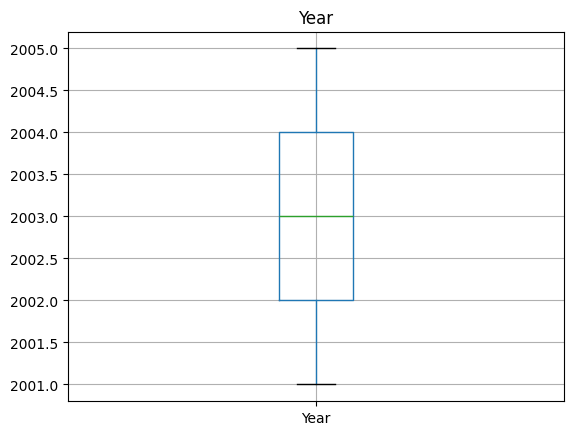

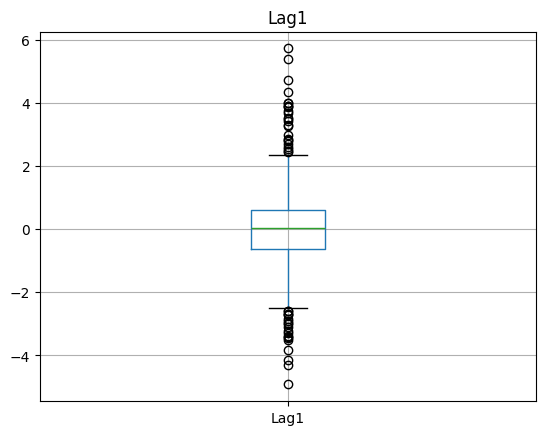

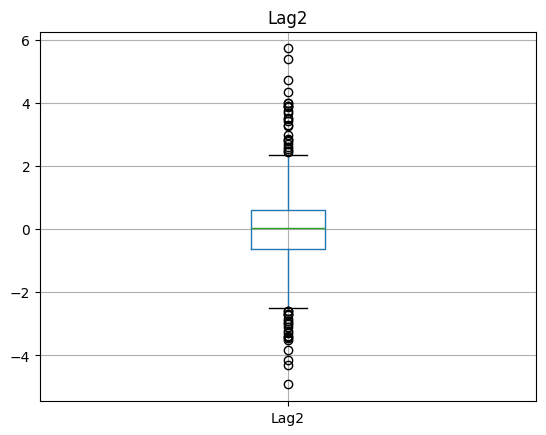

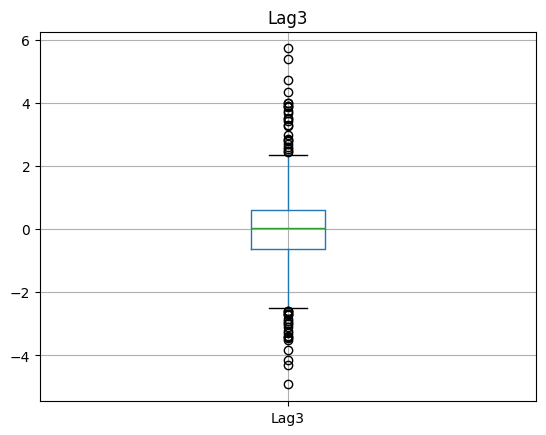

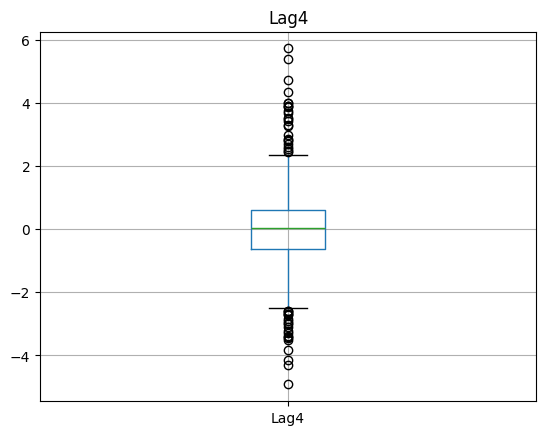

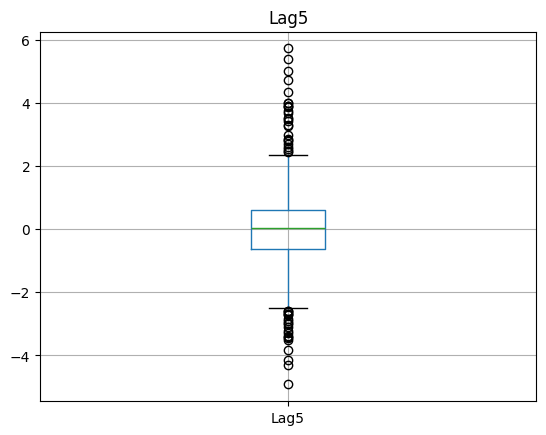

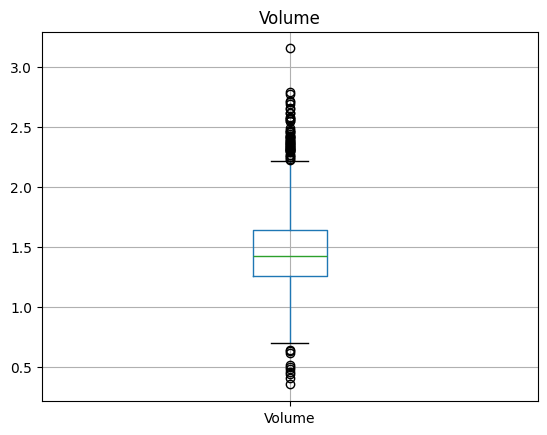

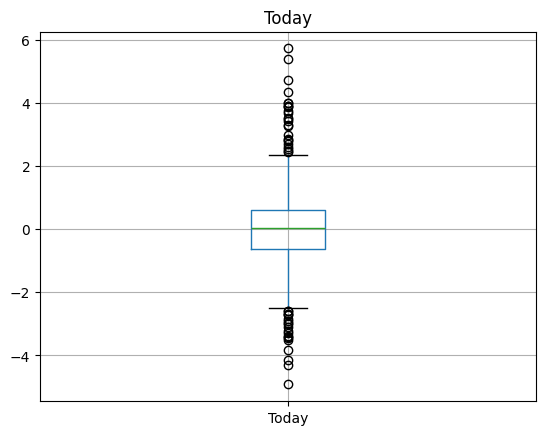

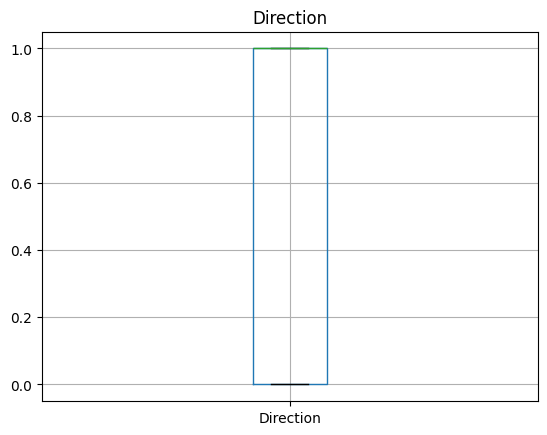

In [ ]:
df = pd.read_csv("/Smarket.csv")
print(df.info())
print(df["Direction"].value_counts())
print(df)

# Since the datatype of target variable is object and gives away 2 types of outputs, mapping them to either 0 or 1 (binary classification problem)
df["Direction"] = df["Direction"].map({
    "Up": 1,
    "Down": 0
})

for col in df.columns:
  df.boxplot(column = col)
  plt.title(col)
  plt.show()

### 3. Train/test split and robust feature scaling
**Split:** 75% of rows are randomly sampled (fixed `random_state` for reproducibility) as the training set; the remaining 25% form the test set → 938 train / 312 test rows.

**Feature Selection:** Target feature ``Direction`` has been dropped from the input feature and ``Today`` has also been dropped because it literally indicates the ``Direction``. All the features except ``Direction`` give us ~96% accuracy which is mostly data leakage due to ``Today`` feature which gives away ``Direction``. Then it falls to around ~54% accuracy which is well-known for this dataset.

**Scaling:** Because the features contain many outliers, *robust scaling* is used instead of min–max or z-score scaling. It relies on the median and interquartile range, which outliers barely affect:

$$x_{scaled} = \frac{x - \text{median}(x)}{Q_3 - Q_1}$$

The median and IQR are computed **only from the training set** and then reused on the test set, so no information from the test data leaks into training.

In [ ]:
# Splitting the dataset by 75:25 (train:test) ratio
train_set = df.sample(frac = .75, random_state = 442)
test_set = df.drop(train_set.index)

# Feature Selection
columns_to_drop = ["Direction", "Today"]

X_train = train_set.drop(columns_to_drop, axis = 1)
y_train = train_set["Direction"].copy()

X_test = test_set.drop(columns_to_drop, axis = 1)
y_test = test_set["Direction"].copy()

print(f"X_train size: {X_train.shape}")
print(f"X_test size: {X_test.shape}")

print(f"y_train size: {y_train.shape}")
print(f"y_test size: {y_test.shape}")

# using robust feature scaling since the features contain a lot of outliers

median = X_train.median()
q1 = X_train.quantile(.25)
q3 = X_train.quantile(.75)
iqr = q3 - q1

# X_train_scaled = (X_train - X_train.min()) / (X_train.max() - X_train.min())
# X_test_scaled = (X_test - X_test.min()) / (X_test.max() - X_test.min())

X_train_scaled = (X_train - median) / iqr
X_test_scaled = (X_test - median) / iqr


X_train size: (938, 7)
X_test size: (312, 7)
y_train size: (938,)
y_test size: (312,)


### 4. Sigmoid and regularised logistic loss
**Model (hypothesis):** a linear combination of the features is passed through the sigmoid, giving the probability that the market goes up:

$$z^{(i)} = \mathbf{w}\cdot\mathbf{x}^{(i)} + b, \qquad f_{\mathbf{w},b}(\mathbf{x}^{(i)}) = \sigma(z^{(i)}) = \frac{1}{1+e^{-z^{(i)}}}$$

**Loss (binary cross-entropy + L2 regularisation):** `logistic_loss` loops over the $m$ samples to add up the cross-entropy, then adds a penalty on the weights (the bias $b$ is not regularised):

$$J(\mathbf{w},b) = \frac{1}{m}\sum_{i=1}^{m}\Big[-y^{(i)}\log f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - (1-y^{(i)})\log\big(1-f_{\mathbf{w},b}(\mathbf{x}^{(i)})\big)\Big] + \frac{\lambda}{2m}\sum_{j=1}^{n} w_j^2$$

The loss is small when the predicted probability is close to the true label and grows sharply for confident wrong predictions. $\lambda$ (`lbd`) controls how strongly large weights are penalised, which helps prevent overfitting.

In [ ]:
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

def logistic_loss(X, y, w, b, lbd):
  m,n = X.shape
  loss = 0.0
  reg = 0.0
  for i in range(m):
    z = np.dot(X[i], w) + b
    f_wb = sigmoid(z)
    loss += -y[i] * np.log(f_wb) - (1 - y[i]) * np.log(1 - f_wb)

  for i in range(n):
    reg += w[i] ** 2

  reg_term = (lbd / (2 * m)) * reg
  total_cost = (loss / m) + reg_term

  return total_cost

### 5. Gradient computation and gradient descent
**`gradient_compute`** calculates the partial derivatives of $J$ with respect to each weight and the bias. For every sample the prediction error $f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}$ is accumulated, averaged over $m$, and the regularisation term is added to the weight gradients only:

$$\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_{i=1}^{m}\big(f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}\big)\,x_j^{(i)} + \frac{\lambda}{m}w_j$$

$$\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}\big(f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}\big)$$

**`gradient_descent`** repeats the update below for `iter` iterations, moving the parameters a step of size $\alpha$ (`l_rate`) against the gradient (the direction of steepest decrease of the loss):

$$w_j := w_j - \alpha\frac{\partial J}{\partial w_j}, \qquad b := b - \alpha\frac{\partial J}{\partial b}$$

All parameters are updated simultaneously from the same gradient. Every `iter/10` iterations the current cost and parameters are stored and printed, so convergence can be tracked and plotted later.

In [ ]:
def gradient_compute(X, y, w, b, lbd):
  m,n = X.shape

  dj_dw = np.zeros(n)
  dj_db = 0.0

  for i in range(m):
    z = np.dot(X[i], w) + b
    f_wb = sigmoid(z)
    error = f_wb - y[i]

    dj_db += error

    for j in range(n):
      dj_dw[j] += error * X[i, j]

  dj_dw /= m
  dj_db /= m

  for j in range(n):
    dj_dw[j] += (lbd / m) * w[j]

  return dj_dw, dj_db

def gradient_descent(X_train, y_train, cost_fn, gradient_compute, l_rate, iter, w_i, b_i, lbd):
  J_hist = []
  iterations = []
  parameter_hist = []
  w = w_i
  b = b_i

  for i in range(iter):
    dj_dw, dj_db = gradient_compute(X_train, y_train, w, b, lbd)

    w -= dj_dw * l_rate
    b -= dj_db * l_rate

    if(i%(math.ceil(iter/10)) == 0):
      iterations.append(i)
      J_hist.append(cost_fn(X_train, y_train, w, b, lbd))
      parameter_hist.append([w,b])
      print(f"Iterations: {i} || Cost: {J_hist[-1]}")

  return w, b, J_hist, parameter_hist, iterations

### 6. Prediction
Applies the trained parameters to new data and returns the probability of `Up`: $\hat{p} = \sigma(\mathbf{X}\mathbf{w} + b)$. The probability is converted to a class label later using a 0.5 threshold.

In [ ]:
def predict(w, X, b):
  return sigmoid(np.dot(X, w) + b)

### 7. Training with different regularisation strengths and evaluating accuracy
- The scaled DataFrames / Series are converted to NumPy arrays so they can be indexed as `X[i]`, `y[i]` inside the loops.
- The model is trained from scratch (weights and bias reset to 0) for each $\lambda \in \{0.01, 0.05, \dots, 100\}$, with learning rate $\alpha = 0.01$ and 1000 iterations. The recorded cost history for each $\lambda$ is saved in `loss_history`.
- Predicted probabilities are thresholded to class labels:

$$\hat{y} = \begin{cases}1 & \text{if } \sigma(\mathbf{w}\cdot\mathbf{x}+b) \ge 0.5\\ 0 & \text{otherwise}\end{cases}$$

- Accuracy on both train and test sets is computed as $\text{Accuracy} = \frac{\text{number of correct predictions}}{\text{total predictions}} \times 100\%$.

Comparing train vs test accuracy across $\lambda$ shows the effect of regularisation: small $\lambda$ lets the model fit freely, while very large $\lambda$ shrinks the weights so much that the loss stays higher and accuracy starts to drop.

In [ ]:
X_np = X_train_scaled.to_numpy()
X_test_np = X_test_scaled.to_numpy()

y_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

m,n = X_np.shape

w = np.zeros(n)
b = 0.0

loss_history = {}
reg_parameters = [0.01, 0.05, 0.1, 0.2, 0.5, 1, 5, 10, 20, 50, 100]

for reg in reg_parameters:
  w = np.zeros(n)
  b = 0.0
  w, b, J_hist, parameter_hist, iterations = gradient_descent(X_np, y_np, logistic_loss, gradient_compute, .01, 1000, w, b, reg)
  loss_history[reg] = J_hist

  y_train_prob = predict(w, X_np, b)
  y_train_pred = np.where(y_train_prob >= .5, 1, 0)
  y_train_pred = y_train_pred.flatten()

  y_test_prob = predict(w, X_test_np, b)
  y_test_pred = np.where(y_test_prob >= .5, 1, 0)
  y_test_pred = y_test_pred.flatten()

  is_correct_train = (y_train_pred == y_train)
  is_correct_test = (y_test_pred == y_test_np)

  true_count_train = np.count_nonzero(is_correct_train == True)
  true_count_test = np.count_nonzero(is_correct_test == True)

  print(f"Train accuracy: {(true_count_train / len(is_correct_train)) * 100}%")
  print(f"Test accuracy: {(true_count_test / len(is_correct_test)) * 100}%")
  print("\n\n")


Iterations: 0 || Cost: 0.6931241930781683
Iterations: 100 || Cost: 0.6912751696222443
Iterations: 200 || Cost: 0.6900704902455436
Iterations: 300 || Cost: 0.6892600610701234
Iterations: 400 || Cost: 0.6886959796916609
Iterations: 500 || Cost: 0.6882896250526968
Iterations: 600 || Cost: 0.6879870464920026
Iterations: 700 || Cost: 0.6877547970409638
Iterations: 800 || Cost: 0.6875717139181537
Iterations: 900 || Cost: 0.6874241007256202
Train accuracy: 52.66524520255863%
Test accuracy: 50.641025641025635%



Iterations: 0 || Cost: 0.6931241930816795
Iterations: 100 || Cost: 0.6912752242538723
Iterations: 200 || Cost: 0.6900706603563515
Iterations: 300 || Cost: 0.6892603669909475
Iterations: 400 || Cost: 0.6886964235138435
Iterations: 500 || Cost: 0.688290201258244
Iterations: 600 || Cost: 0.6879877468760572
Iterations: 700 || Cost: 0.6877556128790122
Iterations: 800 || Cost: 0.6875726368317214
Iterations: 900 || Cost: 0.6874251229561334
Train accuracy: 52.66524520255863%
Test accuracy: 50

### 8. Visualising the training loss
Plots the stored cost (sampled every 100 iterations) against the logging step for every $\lambda$ on one figure. A steadily decreasing curve confirms that gradient descent is converging; curves that flatten at a higher value correspond to larger $\lambda$, where the regularisation penalty dominates the loss.

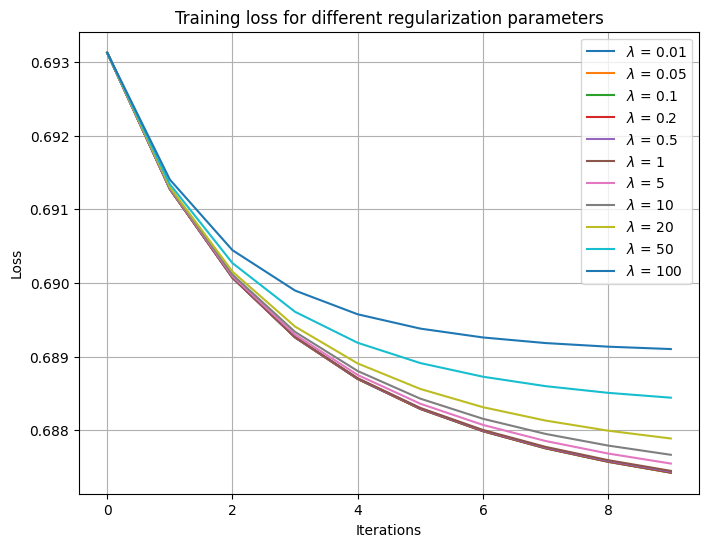

In [ ]:
plt.figure(figsize = (8,6))

for reg,losses in loss_history.items():
  plt.plot(losses, label = f"$\\lambda$ = {reg}")

plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Training loss for different regularization parameters")
plt.grid(True)
plt.legend()
plt.show()

### 9. Learning-rate comparison with more iterations
The runs above use a single learning rate ($\alpha = 0.01$) for 1000 iterations, and the loss is still falling at the end. This section keeps $\lambda$ fixed and trains the model with several learning rates for **3000 iterations**, to see how $\alpha$ affects convergence speed.

Here only the step size differs:

$$w_j := w_j - \alpha\frac{\partial J}{\partial w_j}, \qquad b := b - \alpha\frac{\partial J}{\partial b}$$

- **Too small $\alpha$:** each step is tiny, so the loss decreases very slowly and may not converge within the iteration budget.
- **Well-chosen $\alpha$:** the loss drops quickly and levels off.
- **Too large $\alpha$:** steps overshoot the minimum, so the loss can oscillate or even diverge.

Weights and bias are reset to 0 for every run, so all learning rates start from the same point. For each run the final loss and train/test accuracy are recorded.

In [ ]:
lr_options = [0.001, 0.01, 0.05, 0.1, 0.5]
lr_iterations = 3000
lr_lambda = 0.1

lr_loss_history = {}
lr_iteration_steps = {}
lr_results = []

for lr in lr_options:
  print(f"Learning rate: {lr}")
  w = np.zeros(n)
  b = 0.0
  w, b, J_hist, parameter_hist, iterations = gradient_descent(X_np, y_np, logistic_loss, gradient_compute, lr, lr_iterations, w, b, lr_lambda)
  lr_loss_history[lr] = J_hist
  lr_iteration_steps[lr] = iterations

  y_train_pred = np.where(predict(w, X_np, b) >= .5, 1, 0)
  y_test_pred = np.where(predict(w, X_test_np, b) >= .5, 1, 0)

  train_acc = np.mean(y_train_pred == y_np) * 100
  test_acc = np.mean(y_test_pred == y_test_np) * 100
  final_loss = logistic_loss(X_np, y_np, w, b, lr_lambda)

  lr_results.append([lr, final_loss, train_acc, test_acc])
  print(f"Train accuracy: {train_acc:.2f}%")
  print(f"Test accuracy: {test_acc:.2f}%")
  print("\n\n")

lr_summary = pd.DataFrame(lr_results, columns = ["Learning rate", "Final loss", "Train accuracy (%)", "Test accuracy (%)"])
print(lr_summary.to_string(index = False))

Learning rate: 0.001
Iterations: 0 || Cost: 0.6931448794506989
Iterations: 300 || Cost: 0.692499596516179
Iterations: 600 || Cost: 0.6919354799032472
Iterations: 900 || Cost: 0.6914410572919133
Iterations: 1200 || Cost: 0.6910065615338399
Iterations: 1500 || Cost: 0.6906236727453611
Iterations: 1800 || Cost: 0.690285298900224
Iterations: 2100 || Cost: 0.6899853895554383
Iterations: 2400 || Cost: 0.6897187779375618
Iterations: 2700 || Cost: 0.6894810472040529
Train accuracy: 52.56%
Test accuracy: 50.96%



Learning rate: 0.01
Iterations: 0 || Cost: 0.6931241930860683
Iterations: 300 || Cost: 0.6892607493250669
Iterations: 600 || Cost: 0.6879886220764784
Iterations: 900 || Cost: 0.6874264001781364
Iterations: 1200 || Cost: 0.6871195271448489
Iterations: 1500 || Cost: 0.6869320494499923
Iterations: 1800 || Cost: 0.6868114523983263
Iterations: 2100 || Cost: 0.6867321162638925
Iterations: 2400 || Cost: 0.6866794104837751
Iterations: 2700 || Cost: 0.6866442419993521
Train accuracy: 52.77%
Te

### 10. Visualising the learning-rate comparison
Plots the training loss against the actual iteration number for each learning rate. The fastest-falling curve that still decreases smoothly indicates the best learning rate for this problem; a curve that is still sloping down at 3000 iterations needs a larger $\alpha$ or more iterations, while a curve that jumps around indicates $\alpha$ is too large.

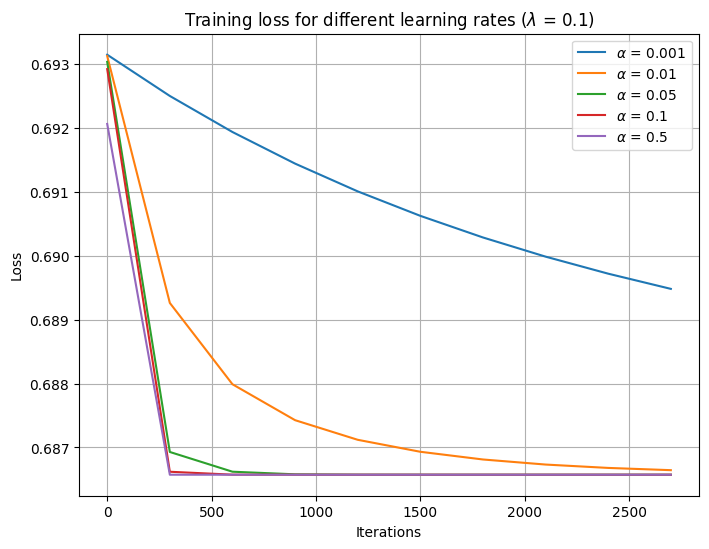

In [ ]:
plt.figure(figsize = (8,6))

for lr, losses in lr_loss_history.items():
  plt.plot(lr_iteration_steps[lr], losses, label = f"$\\alpha$ = {lr}")

plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title(f"Training loss for different learning rates ($\\lambda$ = {lr_lambda})")
plt.grid(True)
plt.legend()
plt.show()